# Demo LightGlue

Github Repositories
- LightGlue: https://github.com/cvg/LightGlue  
- hpatches dataset: https://github.com/hpatches/hpatches-dataset

In [1]:
# Clone Github repository
import os
import importlib.util
import sys
from IPython.display import clear_output
if not os.path.exists("external/LightGlue"):
    !git clone https://github.com/cvg/LightGlue.git external/LightGlue

# list packages, if not lightglue install it
if importlib.util.find_spec("lightglue") is None:
    %pip install ./external/LightGlue

if not os.path.exists("data/hpatches-sequences-release"):
  # Download and extract HPatches Sequences
  if not os.path.exists("hpatches-sequences-release.zip"):
    !wget https://huggingface.co/datasets/vbalnt/hpatches/resolve/main/hpatches-sequences-release.zip
  !7z x hpatches-sequences-release.zip -odata
clear_output()


## Introduction to LightGLUE: The Neural Matcher

**LightGLUE** is a state-of-the-art deep neural network designed to match local features across images. Acting as a lightweight, faster, and more efficient successor to the popular SuperGlue model, it relies on Transformer-based attention layers to understand the global context of a scene. This allows it to easily resolve ambiguities and find highly accurate correspondences that traditional matchers would miss.

The defining feature of LightGLUE is its **adaptive computation**. Unlike previous models that run a fixed number of heavy computations for every image pair, LightGLUE dynamically adjusts its workload based on the difficulty of the images. It actively drops points it deems unmatchable and exits the network early if it is already confident in the matches, giving you peak accuracy at a fraction of the computational cost.

Because LightGLUE is so highly tunable, you can easily control how it behaves:

> **Key Hyperparameters to Tune LightGlue (The Speed vs. Accuracy Tradeoff):**
>  * `n_layers` *(default: 9)*: The total number of attention layers. Reducing this yields faster inference but lower accuracy on difficult image pairs.
>  * `depth_confidence` *(default: 0.95)*: Controls early stopping. A lower value forces the network to stop computing earlier layers once it feels confident, saving compute time. Set to `-1` to disable.
>  * `width_confidence` *(default: 0.99)*: Controls the iterative point pruning. A lower value aggressively prunes "unmatchable" points earlier in the network. Set to `-1` to disable.
>  * `filter_threshold` *(default: 0.1)*: The final match confidence threshold. Increase this value (e.g., to `0.2` or higher) if you want fewer, but much stronger/stricter matches.
>  * `flash` *(default: True)*: Enables FlashAttention. If your hardware supports it, this significantly increases speed and reduces memory consumption without any impact on accuracy.

## Helper functions

In [2]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import matplotlib
from matplotlib import cm

from lightglue.utils import load_image, rbd

def getHpatchesPairPaths(root, category, pair_idx=2):
    assert pair_idx > 1 or pair_idx < 6, "pair_idx must be in [2, 3, 4, 5]"
    ###################################
    image1_path = f"{root}/{category}/1.ppm"
    image2_path = f"{root}/{category}/{pair_idx}.ppm"
    H12_path = f"{root}/{category}/H_1_{pair_idx}"
    return image1_path, image2_path, H12_path

def print_feat_stats(feats0, feats1):
    for name, feats in (("Image 1", feats0), ("Image 2", feats1)):
        image_size = feats["image_size"].squeeze().tolist()
        scales = feats["scales"].squeeze()

        print(f"{name}")
        # print(f"  Image size: {int(image_size[0])} × {int(image_size[1])}")
        print(f"  Image size: {image_size[0]} × {image_size[1]}")
        print(f"  Keypoints:  {feats['keypoints'].shape[1]}")
        print(f"  Descriptors: {tuple(feats['descriptors'].shape)}")
        print(
            f"  Scales:     min={scales.min().item():.2f}, "
            f"max={scales.max().item():.2f}, "
            f"mean={scales.mean().item():.2f}"
        )
        print()

def drawKeypoints(image, feats, ax=None, color="r", s=1):
    if ax is None:
        fig, ax = plt.subplots(1, 1)
    ax.imshow(image.permute(1, 2, 0).cpu().numpy())
    kpts = feats["keypoints"].cpu().numpy()
    if kpts.ndim == 3:
        kpts = kpts[0]
    ax.scatter(kpts[:, 0], kpts[:, 1], s=s, c=color, alpha=0.5)
    return ax

def drawKeypointsPair(image0, feats0, image1, feats1, ax=None, color="r", s=1):
    w1, h1 = image0.shape[2], image0.shape[1]
    w2, h2 = image1.shape[2], image1.shape[1]
    fig, ax = plt.subplots(1, 2, figsize=(12, 6),
        gridspec_kw={"width_ratios": [w1 / h1, w2 / h2]},
        constrained_layout=True,
    )
    drawKeypoints(image0, feats0, ax=ax[0], color=color, s=s)
    drawKeypoints(image1, feats1, ax=ax[1], color=color, s=s)
    plt.tight_layout()
    plt.show()

def drawMatches(image0, points0, image1, points1, ax=None):
    w1, h1 = image0.shape[2], image0.shape[1]
    w2, h2 = image1.shape[2], image1.shape[1]
    fig, ax = plt.subplots(1, 2, figsize=(8, 6),
        gridspec_kw={"width_ratios": [w1 / h1, w2 / h2]},
        constrained_layout=True,
    )
    ax[0].imshow(image0.permute(1, 2, 0).cpu().numpy())
    ax[1].imshow(image1.permute(1, 2, 0).cpu().numpy())

    p0 = points0.detach().cpu().numpy()
    p1 = points1.detach().cpu().numpy()

    ax[0].scatter(p0[:, 0], p0[:, 1], s=2, c="r")
    ax[1].scatter(p1[:, 0], p1[:, 1], s=2, c="r")

    k = 0
    for (x0, y0), (x1, y1) in zip(p0, p1):
        line = matplotlib.patches.ConnectionPatch(
            xyA=(x1, y1), coordsA=ax[1].transData,
            xyB=(x0, y0), coordsB=ax[0].transData,
            color="lime", linewidth=0.5, alpha=0.5
        )
        fig.add_artist(line)
        fig.set_constrained_layout(False)
        k += 1
    plt.tight_layout()
    plt.show()

def getCorrectMatches(points0, points1, H, threshold=3.0):
    # project points0 to image1 using the homography matrix H
    if points0.ndim != 2 or points0.shape[-1] != 2:
        raise ValueError("points0 must have shape (N, 2)")
    if points1.shape != points0.shape:
        raise ValueError("points1 must have the same shape as points0")
    if H.shape != (3, 3):
        raise ValueError("H must have shape (3, 3)")

    if points0.shape[0] == 0:
        print("Number of correct matches: 0 / 0")
        print("Percentage of correct matches: 0.00%")
        return torch.zeros(0, dtype=torch.bool, device=points0.device)

    H = H.to(device=points0.device, dtype=points0.dtype)
    points1 = points1.to(device=points0.device, dtype=points0.dtype)

    ones = torch.ones(
        (points0.shape[0], 1),
        device=points0.device,
        dtype=points0.dtype,
    )
    points0_h = torch.cat([points0, ones], dim=1)
    points0_proj = (H @ points0_h.T).T
    points0_proj = points0_proj[:, :2] / points0_proj[:, 2:3]
    # compute the reprojection error
    reprojection_error = torch.norm(points1 - points0_proj, dim=1)
    correct_matches = reprojection_error < threshold
    print(f"Number of correct matches: {correct_matches.sum().item()} / {points0.shape[0]}")
    print(f"Percentage of correct matches: {correct_matches.sum().item() / points0.shape[0] * 100:.2f}%")
    return correct_matches

c:\Users\carol\miniconda3\envs\cvc\Lib\site-packages\torch\jit\_script.py:1485: FutureWarning: `torch.jit.script` is not supported in Python 3.14+ and may break. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


## Load Data

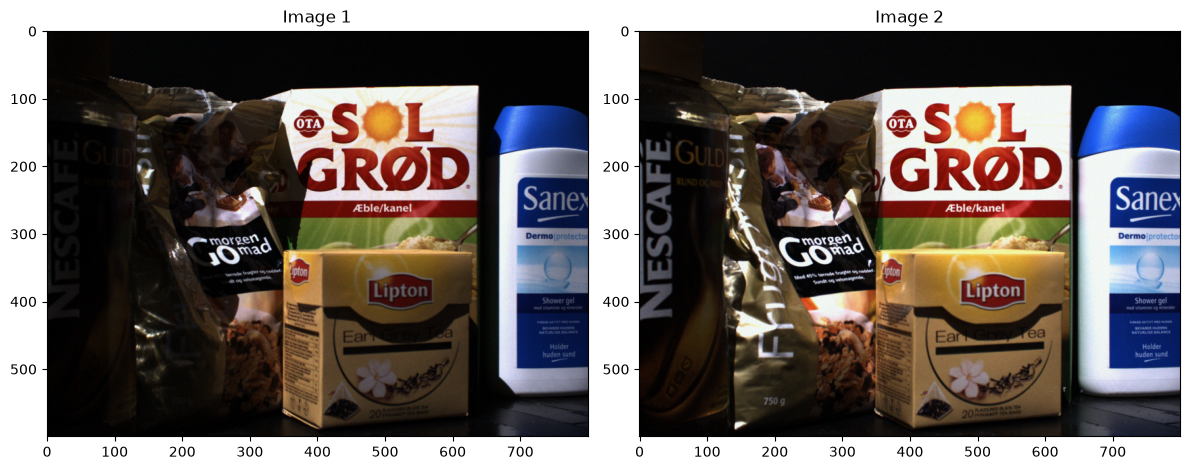

In [9]:
root = "../data/hpatches-sequences-release"

# img1_path, img2_path, h_path = getHpatchesPairPaths(root, "v_bird", pair_idx=2)
# img1_path, img2_path, h_path = getHpatchesPairPaths(root, "i_fog", pair_idx=2)
# img1_path, img2_path, h_path = getHpatchesPairPaths(root, "v_wall", pair_idx=2)
# img1_path, img2_path, h_path = getHpatchesPairPaths(root, "v_dogman", pair_idx=6)
img1_path, img2_path, h_path = getHpatchesPairPaths(root, "i_nescafe", pair_idx=3)

# read images and homography matrix
image0 = load_image(img1_path)
image1 = load_image(img2_path)
H = torch.from_numpy(np.loadtxt(h_path)).float()

# plot the two images side by side
fig, ax = plt.subplots(1, 2, figsize=(12, 6))
ax[0].imshow(image0.permute(1, 2, 0).cpu().numpy())
ax[0].set_title(f"Image 1")
ax[1].imshow(image1.permute(1, 2, 0).cpu().numpy())
ax[1].set_title(f"Image 2")
plt.tight_layout()


## SIFT + LightGLUE: A Hybrid Pipeline

Local feature matching typically requires two steps: extracting points of interest, and then matching them across images. Here, we are building a hybrid pipeline:

* **The Extractor (SIFT):** We use the classic Scale-Invariant Feature Transform to detect keypoints and compute descriptors. SIFT is heavily optimized, completely training-free, and incredibly robust to scale and rotation changes.
* **The Matcher (LightGLUE):** We replace the traditional Nearest-Neighbor matcher with LightGLUE. LightGLUE is a deep neural network that acts as a faster, more efficient successor to SuperGlue. It uses self-attention to look at the global context of the image, allowing it to easily filter out ambiguous points and find highly accurate correspondences.

**Why this combination?**
Pairing SIFT with LightGLUE demonstrates how we can dramatically upgrade a traditional computer vision pipeline simply by dropping in a modern, AI-driven matcher at the end.

In [10]:
# Import Models
from lightglue import LightGlue, SuperPoint, DISK, SIFT, ALIKED, DoGHardNet

# load the extractor
extractor = SIFT(max_num_keypoints=2048).eval()

# load the matcher
matcher = LightGlue(
    features='sift',
    # n_layers=3,
    # depth_confidence=-1,
    # filter_threshold=0.8,
    # width_confidence=0.99
).eval()

# extract local features
feats0 = extractor.extract(image0)  # auto-resize the image, disable with resize=None
feats1 = extractor.extract(image1)
# print_feat_stats(feats0, feats1)
# drawKeypointsPair(image0, feats0, image1, feats1, color="r", s=1)
with torch.no_grad():
    matches01 = matcher({'image0': feats0, 'image1': feats1})
    feats0, feats1, matches01 = [rbd(x) for x in [feats0, feats1, matches01]]  # remove batch dimension
matches = matches01['matches']  # indices with shape (K,2)
points0 = feats0['keypoints'][matches[..., 0]]  # coordinates in image #0, shape (K,2)
points1 = feats1['keypoints'][matches[..., 1]]  # coordinates in image #1, shape (K,2)
# draw matched points
correct_matches = getCorrectMatches(points0, points1, H, threshold=3.0)

Downloading: "https://github.com/cvg/LightGlue/releases/download/v0.1_arxiv/sift_lightglue.pth" to C:\Users\carol/.cache\torch\hub\checkpoints\sift_lightglue_v0-1_arxiv.pth


100%|██████████| 45.4M/45.4M [00:00<00:00, 114MB/s]


Number of correct matches: 872 / 897
Percentage of correct matches: 97.21%


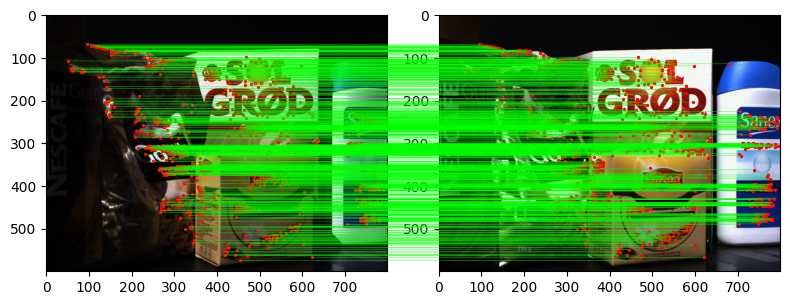

In [ ]:
# Correctly assigned Matches
drawMatches(image0, points0[correct_matches], image1, points1[correct_matches], matches[correct_matches])

## SuperPoint + LightGLUE: An End-to-End Deep Learning Pipeline

Local feature matching requires two steps: extracting points of interest, and matching them across images. While classic methods rely on mathematical formulas, here we are building a fully **end-to-end neural pipeline**:

* **The Extractor (SuperPoint):** Instead of using handcrafted heuristics to find corners, SuperPoint uses a Convolutional Neural Network (CNN) to "learn" what makes a robust keypoint. In a single forward pass, it extracts keypoints, confidence scores, and highly expressive **256-dimensional** descriptors. It excels at finding reliable points even in low-light conditions, motion blur, or textureless scenes.
* **The Matcher (LightGLUE):** We feed SuperPoint's dense outputs into LightGLUE. Acting as a faster, more memory-efficient drop-in replacement for the famous SuperGlue model, LightGLUE uses Transformer attention layers to look at the global context of the images. It understands *where* points are relative to one another, allowing it to filter out ambiguous matches with incredible accuracy.

**Why this combination?**
For years, the SuperPoint + SuperGlue combination was the gold standard in computer vision for tasks like 3D reconstruction and visual localization. By pairing SuperPoint with LightGLUE instead, we keep the immense power of deep-learned features but gain **adaptive computation**. LightGLUE actively drops "unmatchable" points at each layer and stops early on easy image pairs, giving us state-of-the-art accuracy at a fraction of the computational cost.

In [11]:
device= "cuda" if torch.cuda.is_available() else "cpu"
# load the extractor
extractor = SuperPoint(max_num_keypoints=2048).eval().to(device)
# load the matcher
matcher = LightGlue(
    features='superpoint',
    # n_layers=3,
    # depth_confidence=-1,
    # filter_threshold=0.8,
    # width_confidence=0.99
).eval().to(device)

# extract local features
feats0 = extractor.extract(image0.to(device))  # auto-resize the image, disable with resize=None
feats1 = extractor.extract(image1.to(device))
# print_feat_stats(feats0, feats1)
# drawKeypointsPair(image0, feats0, image1, feats1, color="r", s=1)
with torch.no_grad():
    matches01 = matcher({'image0': feats0, 'image1': feats1})
    print(f"StopIteration: {matches01["stop"]}")
    feats0, feats1, matches01 = [rbd(x) for x in [feats0, feats1, matches01]]  # remove batch dimension
matches = matches01['matches']  # indices with shape (K,2)
points0 = feats0['keypoints'][matches[..., 0]]  # coordinates in image #0, shape (K,2)
points1 = feats1['keypoints'][matches[..., 1]]  # coordinates in image #1, shape (K,2)
# draw matched points
correct_matches = getCorrectMatches(points0, points1, H, threshold=3.0)


Downloading: "https://github.com/cvg/LightGlue/releases/download/v0.1_arxiv/superpoint_v1.pth" to C:\Users\carol/.cache\torch\hub\checkpoints\superpoint_v1.pth


100%|██████████| 4.96M/4.96M [00:00<00:00, 79.8MB/s]


Downloading: "https://github.com/cvg/LightGlue/releases/download/v0.1_arxiv/superpoint_lightglue.pth" to C:\Users\carol/.cache\torch\hub\checkpoints\superpoint_lightglue_v0-1_arxiv.pth


100%|██████████| 45.3M/45.3M [00:00<00:00, 67.8MB/s]


StopIteration: 5
Number of correct matches: 1375 / 1424
Percentage of correct matches: 96.56%


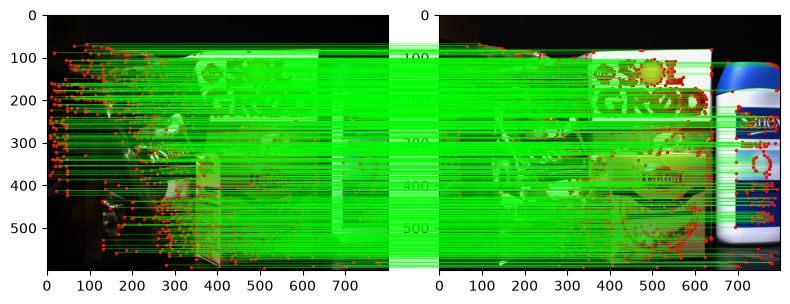

In [12]:
# Correctly assigned Matches
drawMatches(image0, points0[correct_matches], image1, points1[correct_matches], matches[correct_matches])